In [19]:
import pandas as pd
import numpy as np
import sklearn

print("NeuraNex Jupyter Notebook is working!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

NeuraNex Jupyter Notebook is working!
Pandas version: 3.0.6
NumPy version: 2.5.3


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
resumes_df = pd.read_csv("../data/raw/resumes.csv")

print("Dataset loaded successfully!")
print("Shape:", resumes_df.shape)

Dataset loaded successfully!
Shape: (1200, 3)


In [22]:
resumes_df.head()

,resume_id,resume_text,job_category
0,R0001,Experienced professional interested in AI/ML E...,AI/ML Engineer
1,R0002,Experienced professional interested in AI/ML E...,AI/ML Engineer
2,R0003,Experienced professional interested in AI/ML E...,AI/ML Engineer
3,R0004,Experienced professional interested in AI/ML E...,AI/ML Engineer
4,R0005,Experienced professional interested in AI/ML E...,AI/ML Engineer


In [23]:
category_counts = resumes_df["job_category"].value_counts()

category_counts

job_category
AI/ML Engineer            100
Data Analyst              100
Data Scientist            100
Software Developer        100
Web Developer             100
Cybersecurity Analyst     100
Cloud Engineer            100
Database Administrator    100
DevOps Engineer           100
Mobile App Developer      100
QA/Test Engineer          100
Business Analyst          100
Name: count, dtype: int64

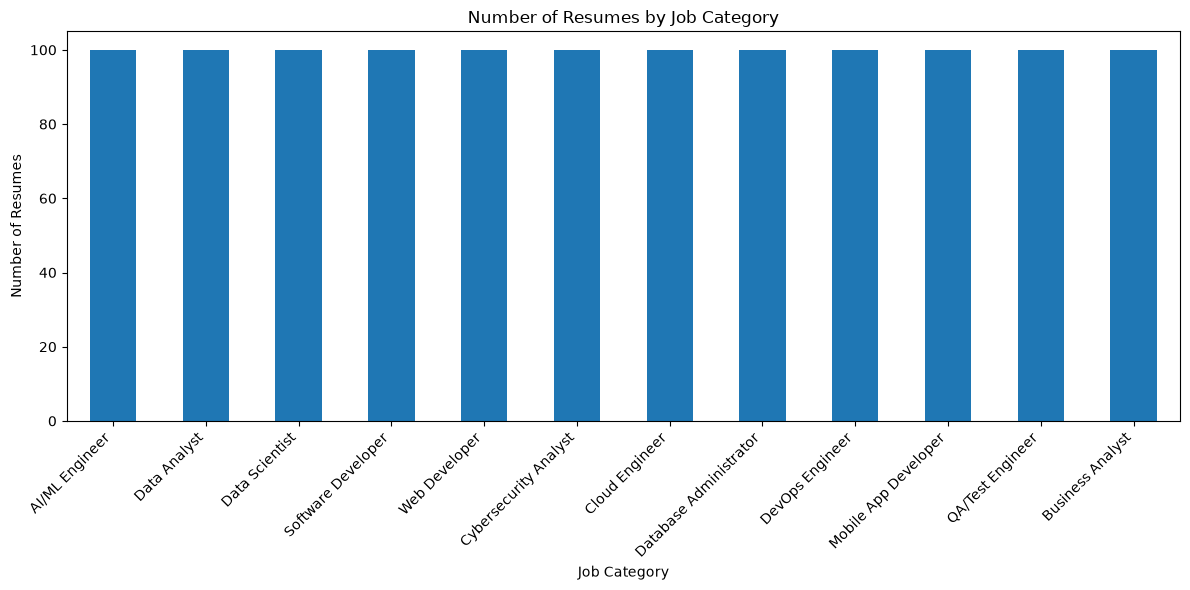

In [24]:
plt.figure(figsize=(12, 6))

category_counts.plot(kind="bar")

plt.title("Number of Resumes by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Number of Resumes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

In [25]:
resumes_df["word_count"] = resumes_df["resume_text"].apply(
    lambda x: len(x.split())
)

resumes_df[["resume_id", "word_count", "job_category"]].head()

,resume_id,word_count,job_category
0,R0001,37,AI/ML Engineer
1,R0002,36,AI/ML Engineer
2,R0003,41,AI/ML Engineer
3,R0004,40,AI/ML Engineer
4,R0005,38,AI/ML Engineer


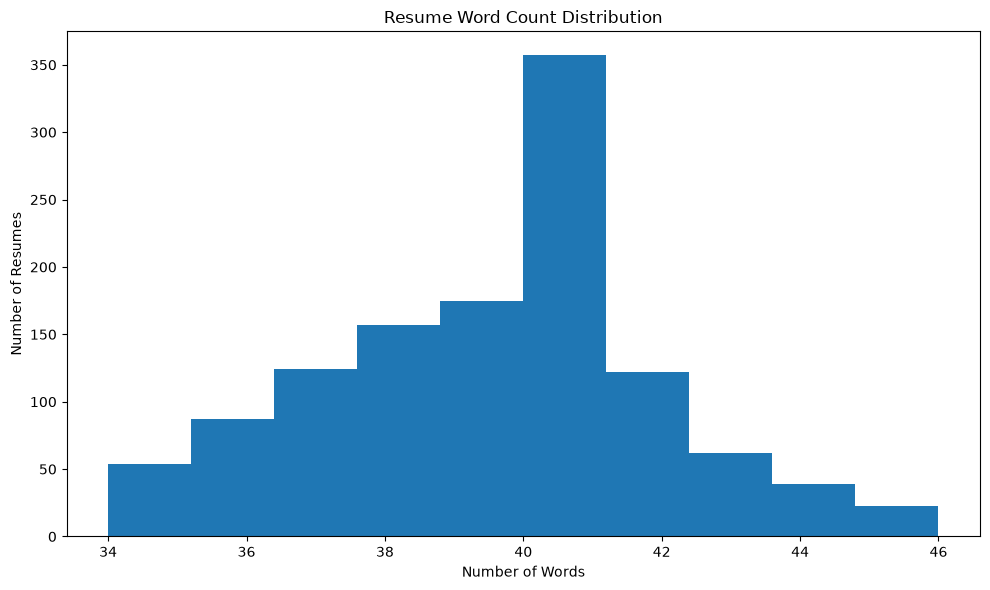

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(resumes_df["word_count"], bins=10)

plt.title("Resume Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Resumes")

plt.tight_layout()
plt.show()

In [27]:
from collections import Counter

all_words = []

for text in resumes_df["resume_text"]:
    all_words.extend(text.split())

word_counts = Counter(all_words)

common_words = word_counts.most_common(20)

common_words

[('and', 2400),
 ('Experienced', 1200),
 ('professional', 1200),
 ('interested', 1200),
 ('in', 1200),
 ('Skills', 1200),
 ('include', 1200),
 ('Worked', 1200),
 ('on', 1200),
 ('academic', 1200),
 ('practical', 1200),
 ('projects', 1200),
 ('involving', 1200),
 ('Familiar', 1200),
 ('with', 1200),
 ('software', 1200),
 ('development', 1200),
 ('practices,', 1200),
 ('problem', 1200),
 ('solving', 1200)]

In [28]:
# Load job descriptions and extract all required skills

jobs_df = pd.read_csv("../data/raw/job_descriptions.csv")

all_skills = set()

for skills in jobs_df["required_skills"]:
    for skill in skills.split(","):
        all_skills.add(skill.strip())

skill_counts = {}

for skill in all_skills:
    count = resumes_df["resume_text"].str.contains(
        skill,
        case=False,
        regex=False
    ).sum()

    skill_counts[skill] = count

skill_frequency = (
    pd.Series(skill_counts)
    .sort_values(ascending=False)
)

skill_frequency

Git                  578
Python               493
SQL                  417
Java                 334
Linux                332
                    ... 
TensorFlow            76
Business Analysis     76
NLP                   76
Kubernetes            74
Algorithms            68
Length: 68, dtype: int64

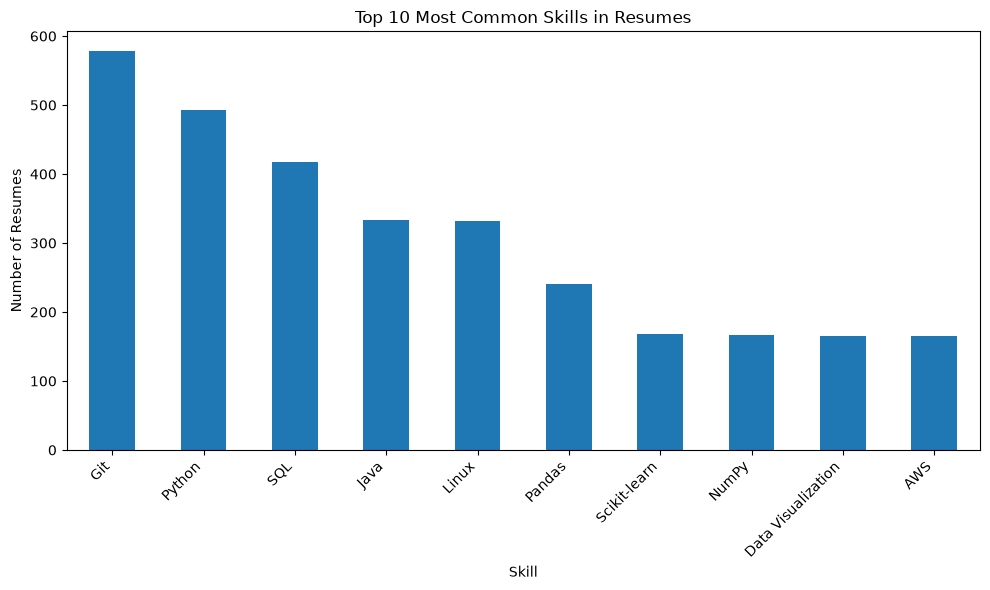

In [29]:
top_10_skills = skill_frequency.head(10)

plt.figure(figsize=(10, 6))

top_10_skills.plot(kind="bar")

plt.title("Top 10 Most Common Skills in Resumes")
plt.xlabel("Skill")
plt.ylabel("Number of Resumes")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [30]:
resumes_df.dtypes

resume_id         str
resume_text       str
job_category      str
word_count      int64
dtype: object

In [18]:
resumes_df.isnull().sum()

resume_id       0
resume_text     0
job_category    0
word_count      0
dtype: int64